# Calibration maps from noisy vs MP-PCA denoised scans

Calculates the calibration maps (A) for each gradient duration twice, using exactly the same pipeline, from
- the registered **noisy** scans (`RAW_REG`), and
- the registered **MP-PCA denoised** scans (`RAW_MPPCA_REG`),

and plots the two sets of maps and their difference. Both sets of scans share the same registration transformations
(see `preprocess_calibration.ipynb`), so any difference comes from the denoising alone.

In [1]:
# Standard libraries
import numpy as np
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from functools import partial

# Specific libraries
import nibabel as nib
import colorcet as cc

# custom functions
import registration as reg
import temperature as temp
import calib_utils as cal

### LOAD DATA

In [2]:
parent_dir = Path("./calibration")
derive_dir = parent_dir / "derivatives"
testname = parent_dir.stem
plot_dir = parent_dir / "plots"
plot_dir.mkdir(exist_ok=True)

param_fname = derive_dir / (testname + "_" + "params.h5")
noisy_fname = derive_dir / (testname + "_" + "RAW_REG.nii.gz")          # registered, noisy scans
denoised_fname = derive_dir / (testname + "_" + "RAW_MPPCA_REG.nii.gz")  # registered, MP-PCA denoised scans
mask_fname = derive_dir / (testname + "_" + "MASK.nii.gz")

# Load in sequence parameters
params_df = pd.read_hdf(param_fname, key="df", mode="r")

# Load in both sets of scans
noisy_nii = nib.load(noisy_fname)
denoised_nii = nib.load(denoised_fname)
scan_aff = noisy_nii.affine
scan_spacing = reg.spacing_from_affine(scan_aff)

if noisy_nii.shape != denoised_nii.shape or noisy_nii.shape[-1] != params_df.shape[0]:
    raise ValueError(f"Scans and parameters don't match: noisy {noisy_nii.shape}, "
                     f"denoised {denoised_nii.shape}, parameter rows {params_df.shape[0]}")

noisy_data = np.transpose(noisy_nii.get_fdata(), [3,0,1,2])
denoised_data = np.transpose(denoised_nii.get_fdata(), [3,0,1,2])

if np.array_equal(noisy_data, denoised_data):
    raise ValueError("The noisy and denoised scans are identical - re-run preprocess_calibration.ipynb "
                     "so that RAW_REG contains the registered noisy scans.")

# Load in mask
mask_nii = nib.load(mask_fname)
mask = mask_nii.get_fdata().astype(int)

# Create a mask slightly inset from threshold based mask to avoid boundary artefacts.
shrink_dist = 6 # mm
core_mask = cal.shrink_mask_mm(mask, voxel_spacing=scan_spacing, margin_mm=shrink_dist)

### CALCULATE CALIBRATION MAPS

In [3]:
def calibration_maps(images, params_df, core_mask, scan_aff, bspline=True):
    """
    Calculate the calibration maps for every gradient duration from a set of registered scans.
    This follows the same steps as calibration_mapping.ipynb.

    :param images: registered scans, [scan, x, y, z], in the same order as the rows of params_df
    :param bspline: if True smooth each gradient map with a B-spline before fitting (as in calibration_mapping.ipynb),
                    if False fit the unsmoothed gradient maps
    :return: dict of {gradient duration: A image [x, y, z, 6]}
    """

    df = params_df.copy()
    df["image"] = list(images)
    df["adc"] = df["temperature"].apply(partial(temp.water_diffusivity, polynomial=True))
    df.sort_values("scan_time", inplace=True, ignore_index=True)

    # Put the b=0 image on b=0 rows, NaN elsewhere
    b0_threshold = 5
    df["s0_image"] = df["image"].where(df["b_value"] < b0_threshold)

    # Forward-fill so each DWI scan gets the most recent preceding b=0 image
    df["s0_image"] = df["s0_image"].ffill()

    # Keep only diffusion-weighted scans
    dwi_df = df[df["b_value"] > b0_threshold].copy()
    dwi_df = dwi_df[dwi_df["s0_image"].notna()].copy()

    dwi_df["bmap"] = dwi_df.apply(lambda row: cal.bmap_3d(s0=row["s0_image"], 
                                                          s=row["image"], 
                                                          adc=row["adc"], 
                                                          mask=core_mask), 
                                                          axis=1)
    dwi_df["cmap"] = dwi_df["bmap"]/dwi_df["b_value"]

    # Estimate gradient maps from b-value maps assuming Stejskal-Tanner Equation applies.
    dwi_df["gmap2"] = dwi_df.apply(lambda row: cal.b2grad2(b=row["bmap"],
                                                  delta_small=row["dwi_grad_duration"],
                                                  delta_big=(row["TE"] / 2),
                                                  mask=core_mask),
                                                  axis=1)

    # Estimate a smoothed version of each gradient map for fitting
    if bspline:
        dwi_df["gmap2_fit"] = dwi_df.apply(lambda row: cal.bspline_estimation(data=row["gmap2"], spacing=row["spacing"], mask=core_mask), axis=1)
    else:
        dwi_df["gmap2_fit"] = dwi_df["gmap2"]

    A_by_duration = {}
    for dur in sorted(dwi_df["dwi_grad_duration"].unique()):

        subset_df = dwi_df[dwi_df["dwi_grad_duration"]==dur].copy()

        input_gvec = np.stack(subset_df["grad_vec"].values, axis=0).astype(np.float32)
        input_gmaps = np.stack(subset_df["gmap2_fit"].values, axis=-1).astype(np.float32)

        A, sigma = cal.calc_calib_maps(input_gvec, input_gmaps, core_mask, as_image=False)
        A_nii = cal.A_as_nifti(A, mask=core_mask, affine=scan_aff, sigma=sigma, P=6)
        A_by_duration[dur] = A_nii.get_fdata()

    return A_by_duration

In [4]:
# With B-spline smoothing of the gradient maps (as in calibration_mapping.ipynb)
print("Calibration maps from noisy scans")
A_noisy = calibration_maps(noisy_data, params_df, core_mask, scan_aff, bspline=True)

print("Calibration maps from denoised scans")
A_denoised = calibration_maps(denoised_data, params_df, core_mask, scan_aff, bspline=True)

# Without B-spline smoothing
print("Calibration maps from noisy scans, no B-spline")
A_noisy_nobs = calibration_maps(noisy_data, params_df, core_mask, scan_aff, bspline=False)

print("Calibration maps from denoised scans, no B-spline")
A_denoised_nobs = calibration_maps(denoised_data, params_df, core_mask, scan_aff, bspline=False)

Calibration maps from noisy scans
Calibration maps from denoised scans
Calibration maps from noisy scans, no B-spline
Calibration maps from denoised scans, no B-spline


### COMPARE

In [5]:
# Order of the maps follows cal.x_from_gvec: [g_x, g_y, g_z, g_x^2, g_y^2, g_z^2]
map_names = [r"$g_x$", r"$g_y$", r"$g_z$", r"$g_x^2$", r"$g_y^2$", r"$g_z^2$"]
core = core_mask.astype(bool)


def summarise(A_n, A_d):
    """
    Summary of how different the maps are within the core mask. The difference is compared to the spatial
    variation of the denoised map, as it is the variation across the field of view that the calibration corrects.
    """
    rows = []
    for dur in A_d:
        for i, name in enumerate(map_names):
            noisy_vals = A_n[dur][..., i][core]
            denoised_vals = A_d[dur][..., i][core]
            diff = noisy_vals - denoised_vals
            rows.append({"duration (ms)": int(round(dur * 1e3)),
                         "map": name,
                         "mean noisy": noisy_vals.mean(),
                         "mean denoised": denoised_vals.mean(),
                         "rms diff": np.sqrt(np.mean(diff**2)),
                         "std denoised": denoised_vals.std(),
                         "rms diff / std denoised (%)": 100 * np.sqrt(np.mean(diff**2)) / denoised_vals.std(),
                         "correlation": np.corrcoef(noisy_vals, denoised_vals)[0, 1]})
    return pd.DataFrame(rows)


summary_df = summarise(A_noisy, A_denoised)
summary_nobs_df = summarise(A_noisy_nobs, A_denoised_nobs)

print("WITH B-spline")
print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.3g}"))
print("\nWITHOUT B-spline")
print(summary_nobs_df.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

WITH B-spline
 duration (ms)     map  mean noisy  mean denoised  rms diff  std denoised  rms diff / std denoised (%)  correlation
            30   $g_x$   -9.05e-06      -8.67e-06  1.98e-06      1.45e-05                         13.6        0.991
            30   $g_y$   -3.47e-06      -3.38e-06  2.14e-06      1.69e-05                         12.7        0.993
            30   $g_z$   -1.13e-05      -1.11e-05  2.15e-06      1.41e-05                         15.3         0.99
            30 $g_x^2$    0.000139       0.000139  2.25e-06      1.22e-05                         18.5        0.986
            30 $g_y^2$    0.000138       0.000138   2.4e-06      1.73e-05                         13.9        0.992
            30 $g_z^2$    0.000146       0.000145  2.35e-06      1.24e-05                           19        0.984
            35   $g_x$    -1.4e-05      -1.42e-05  1.42e-06      8.76e-06                         16.2        0.988
            35   $g_y$     1.4e-06       1.34e-06  1.59e-0

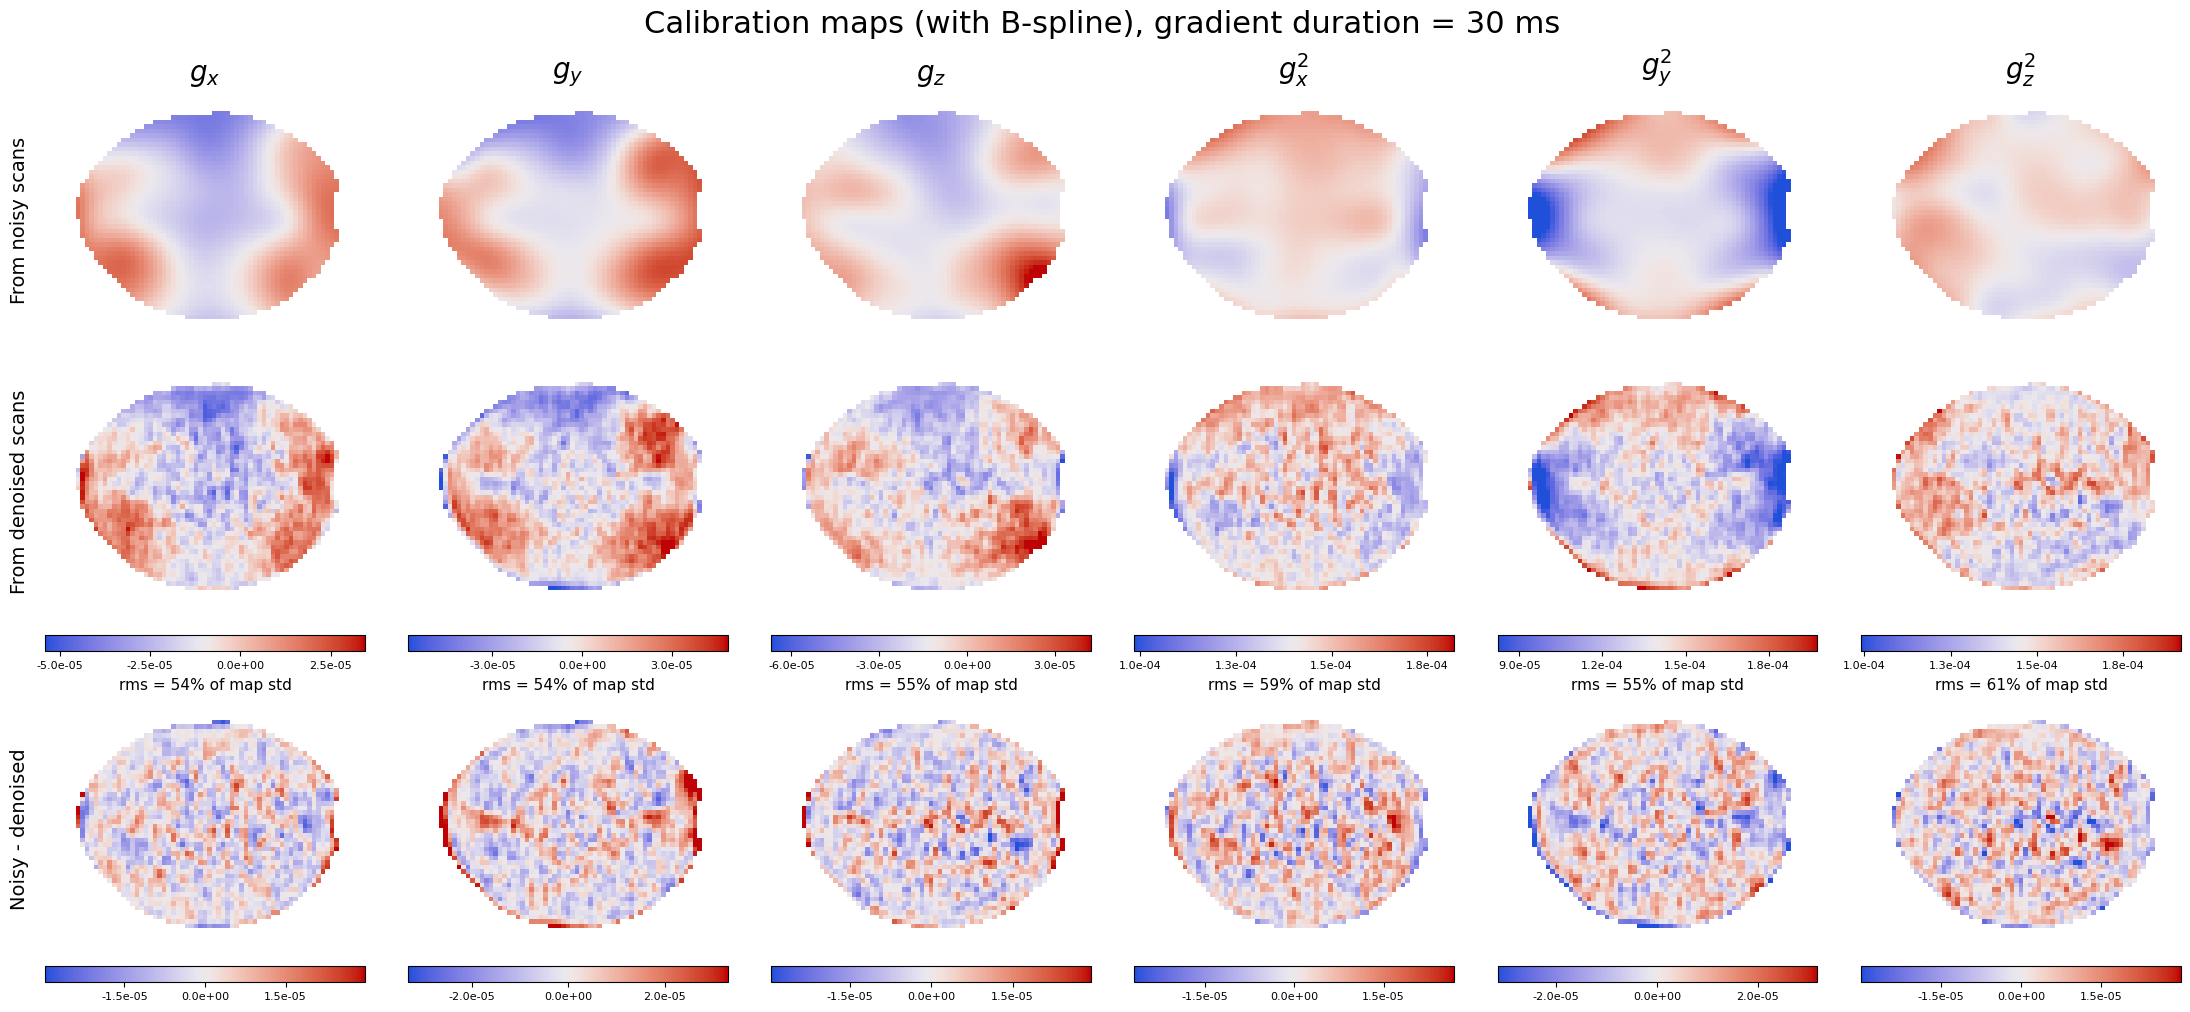

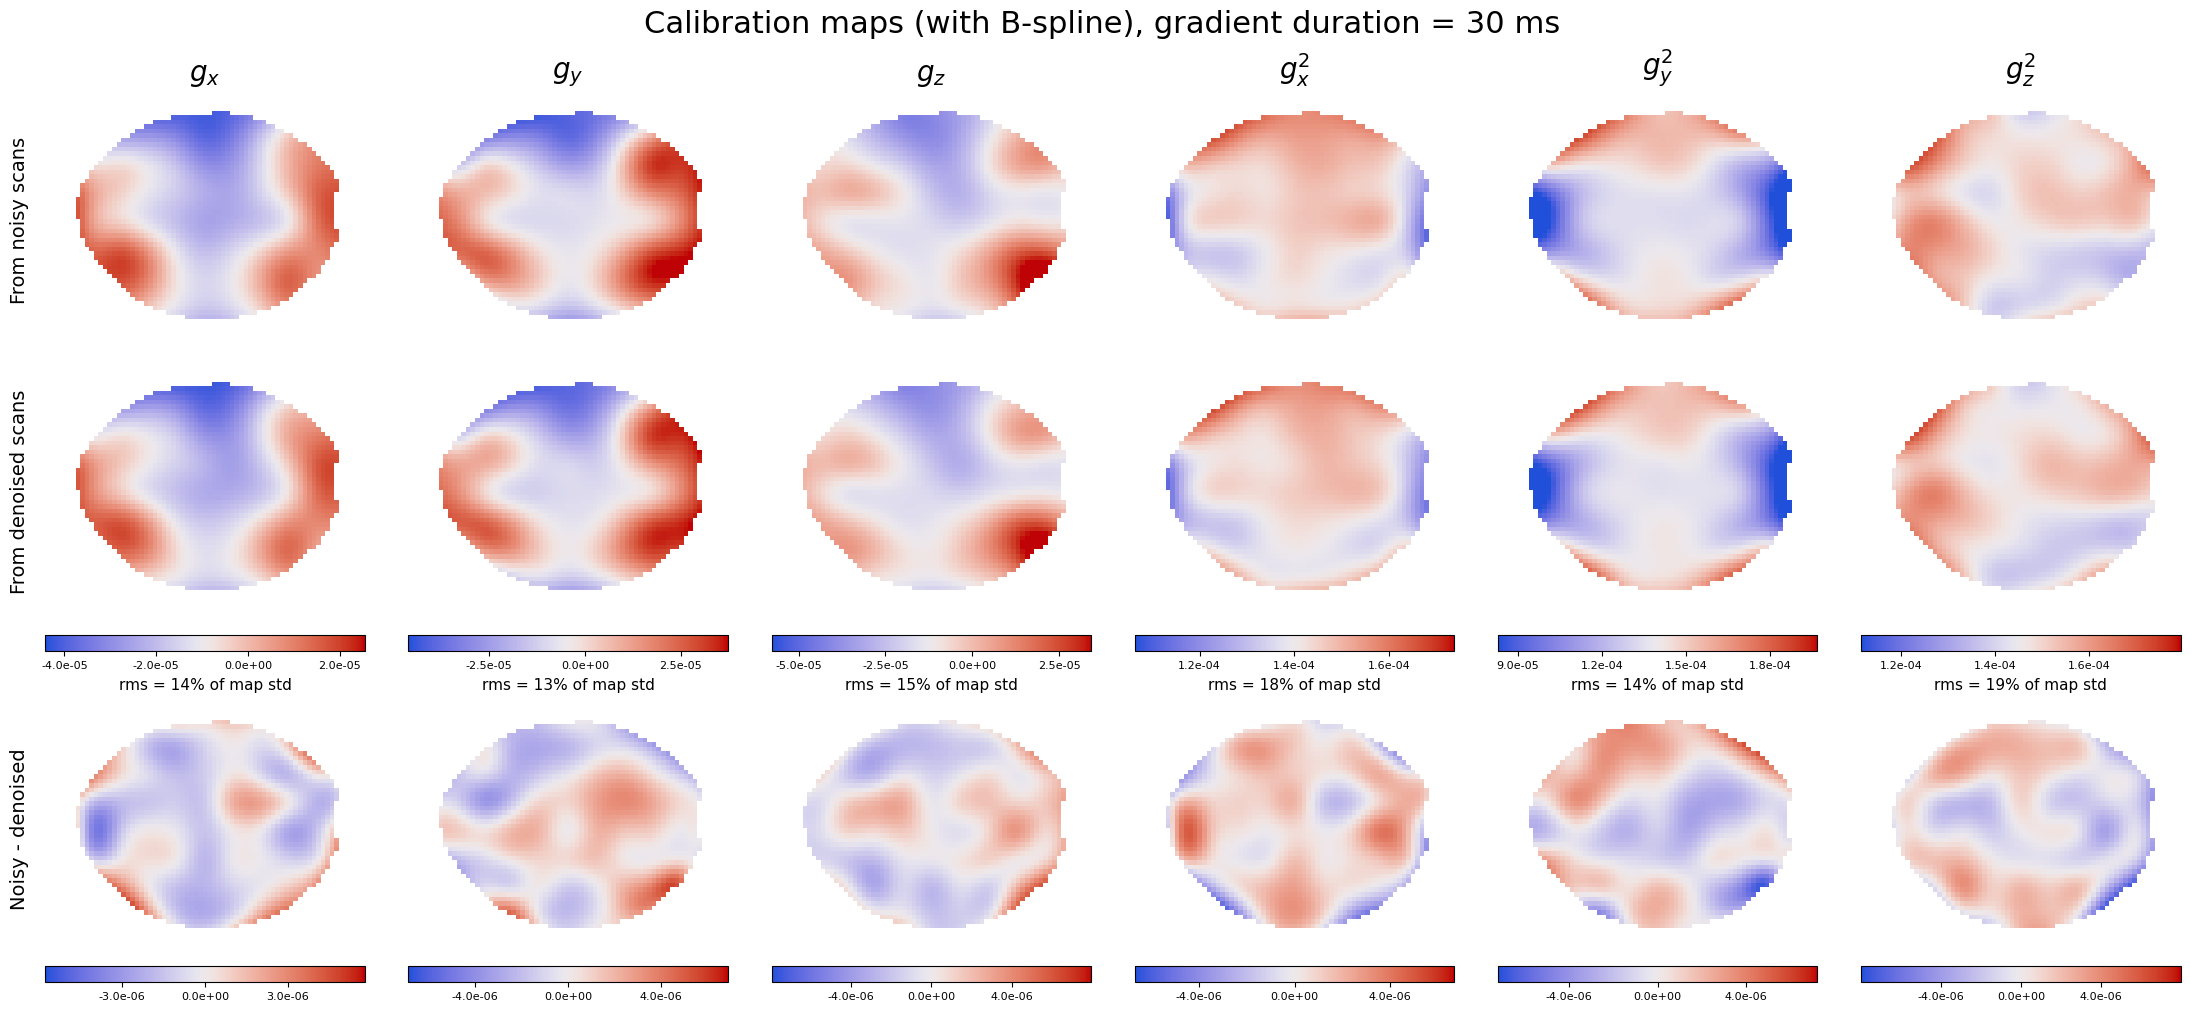

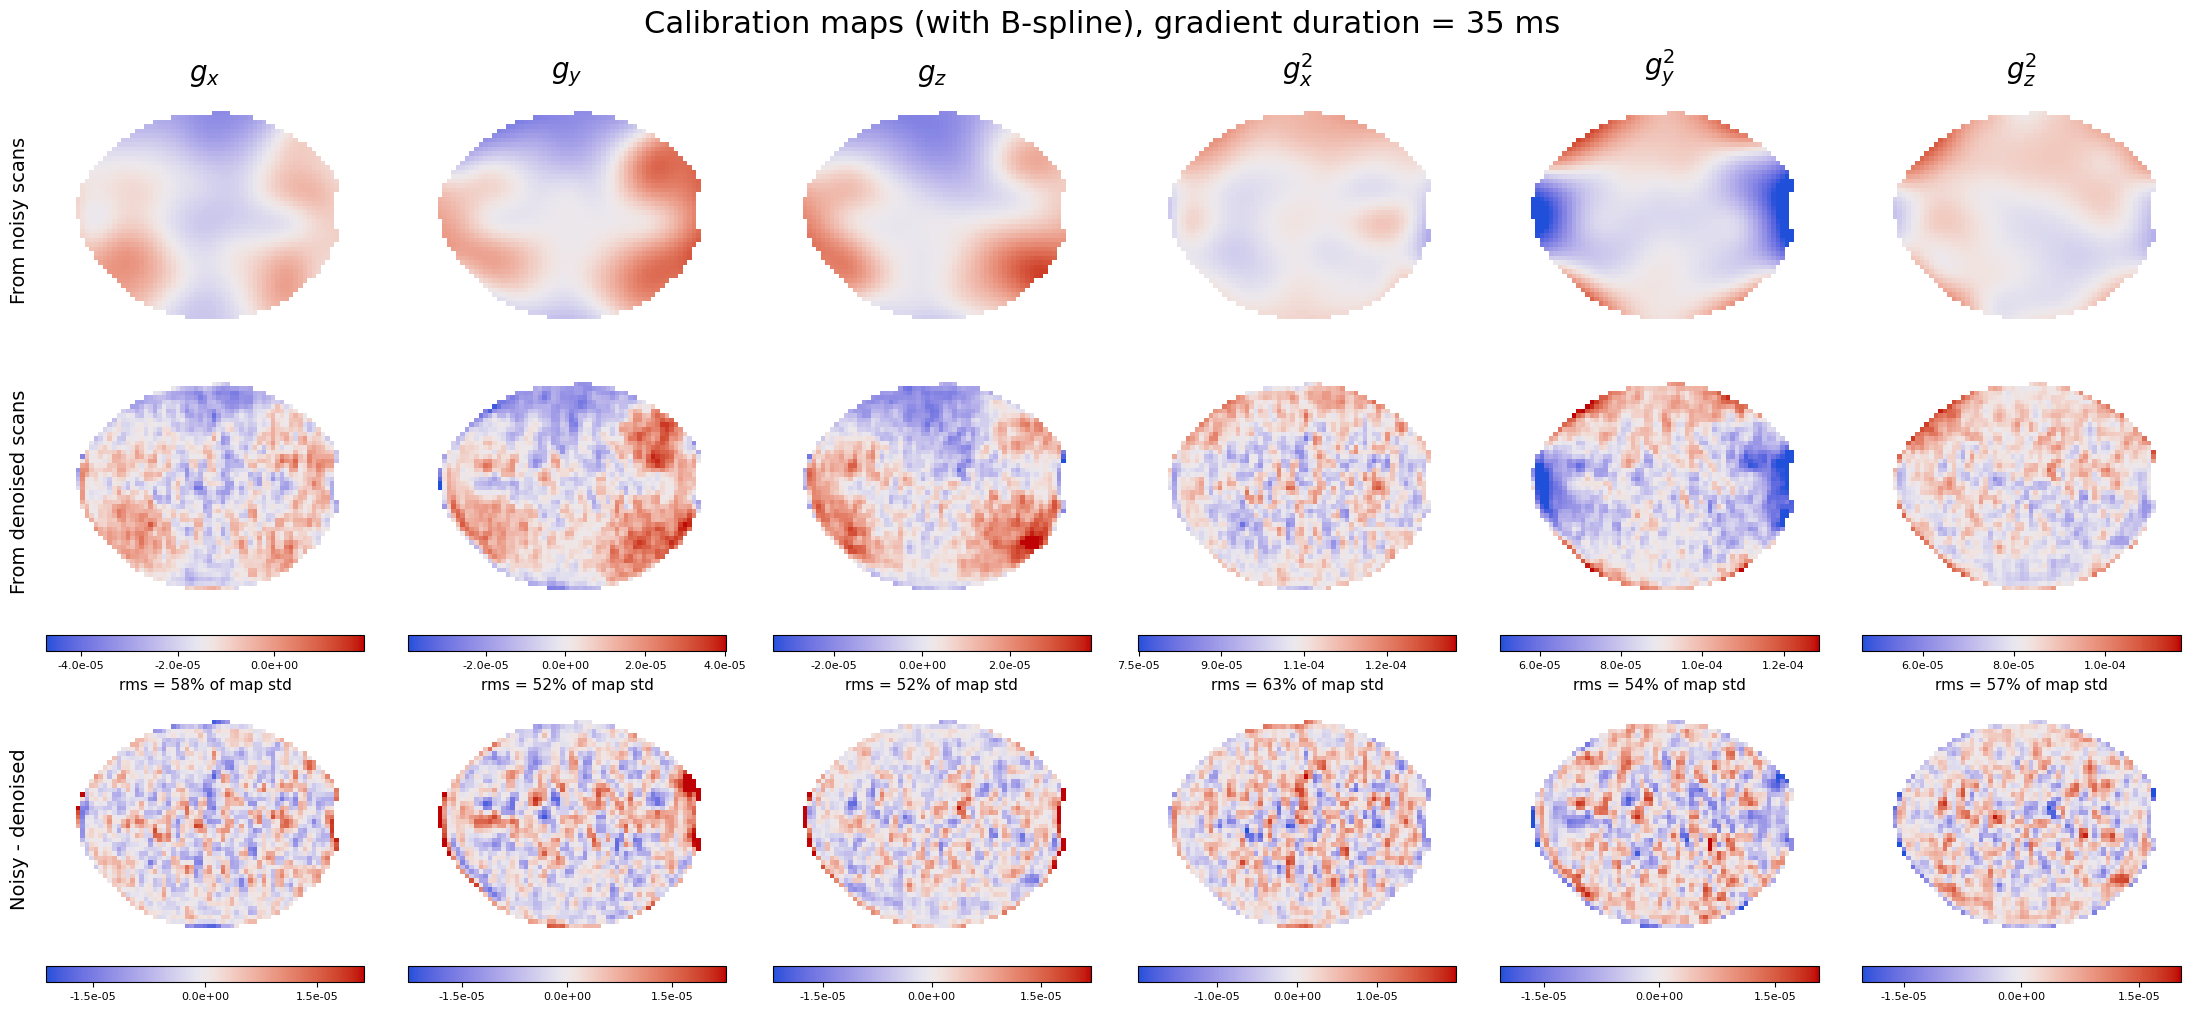

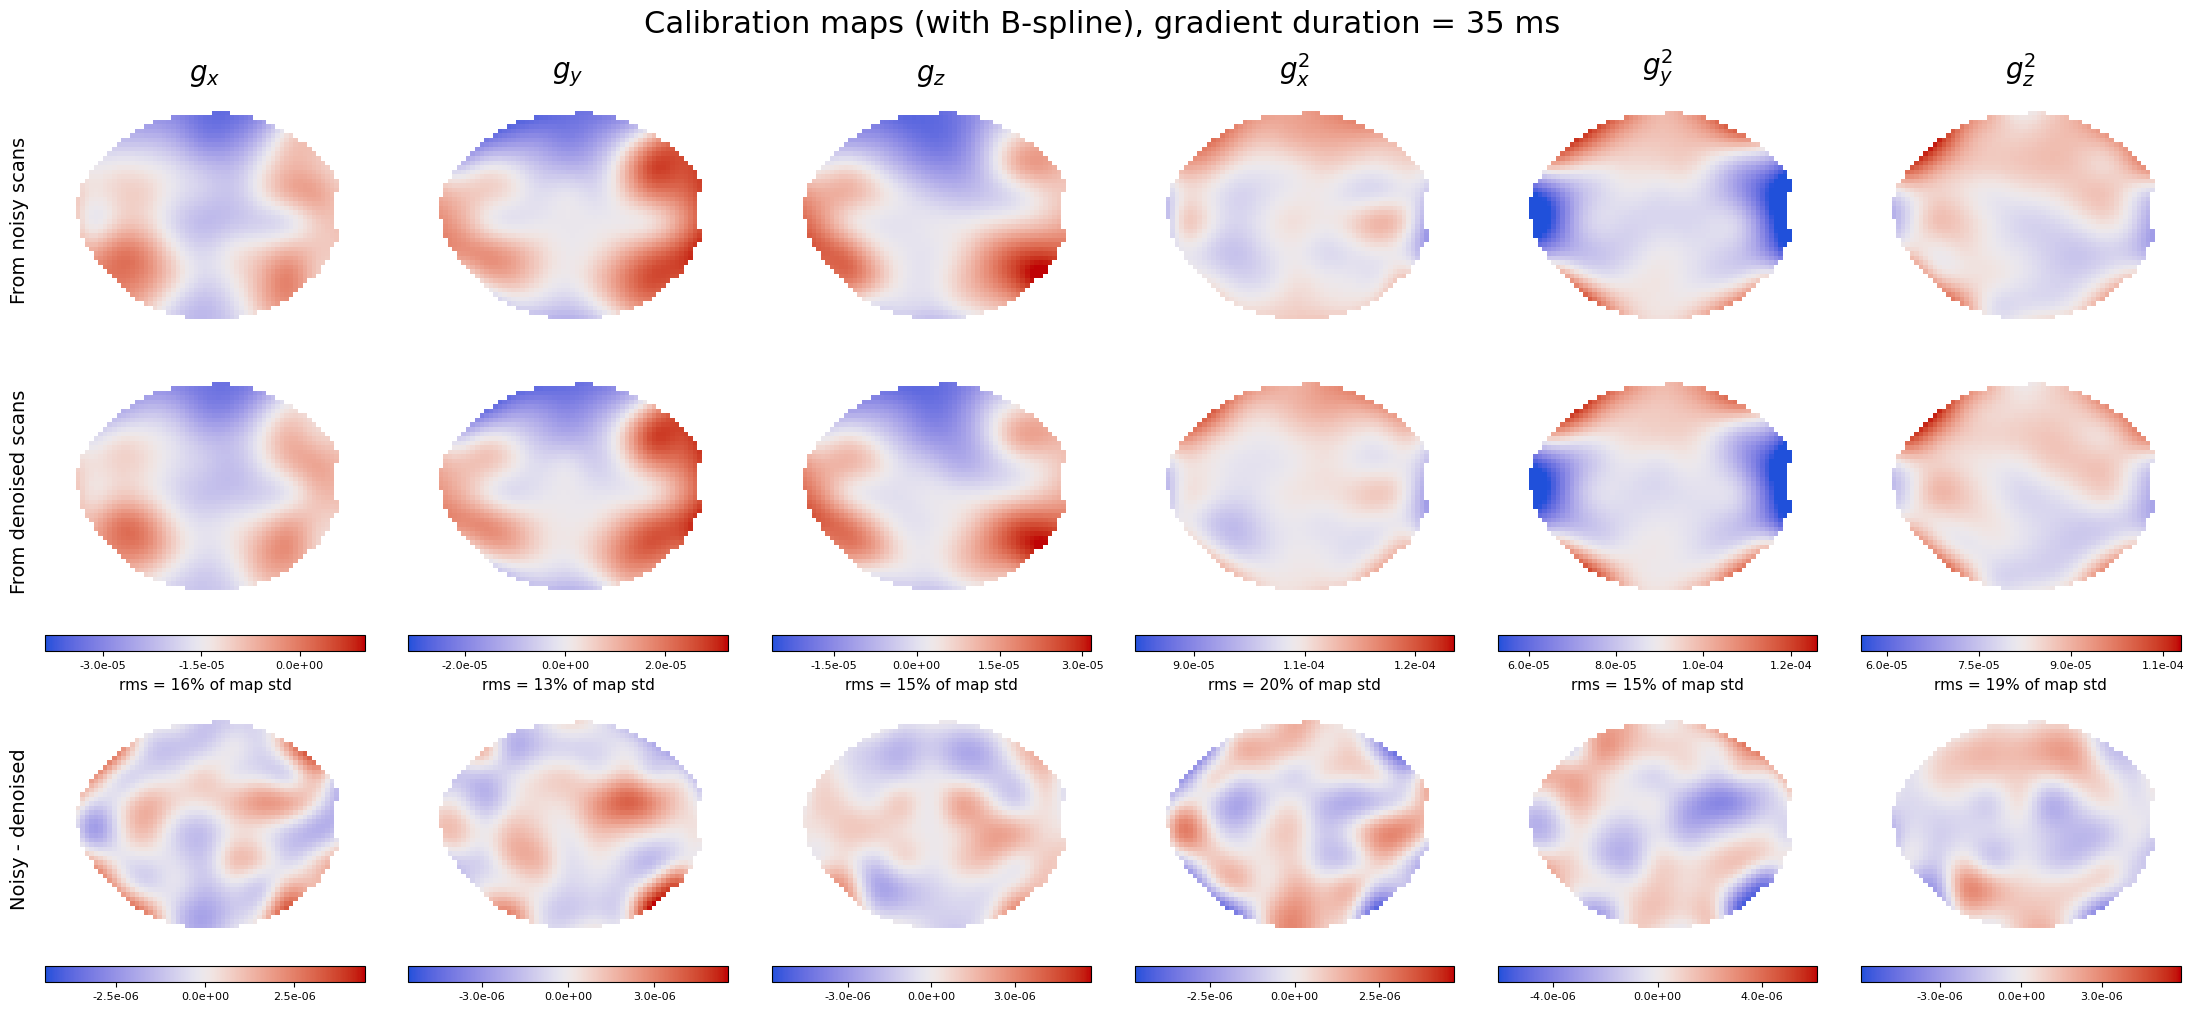

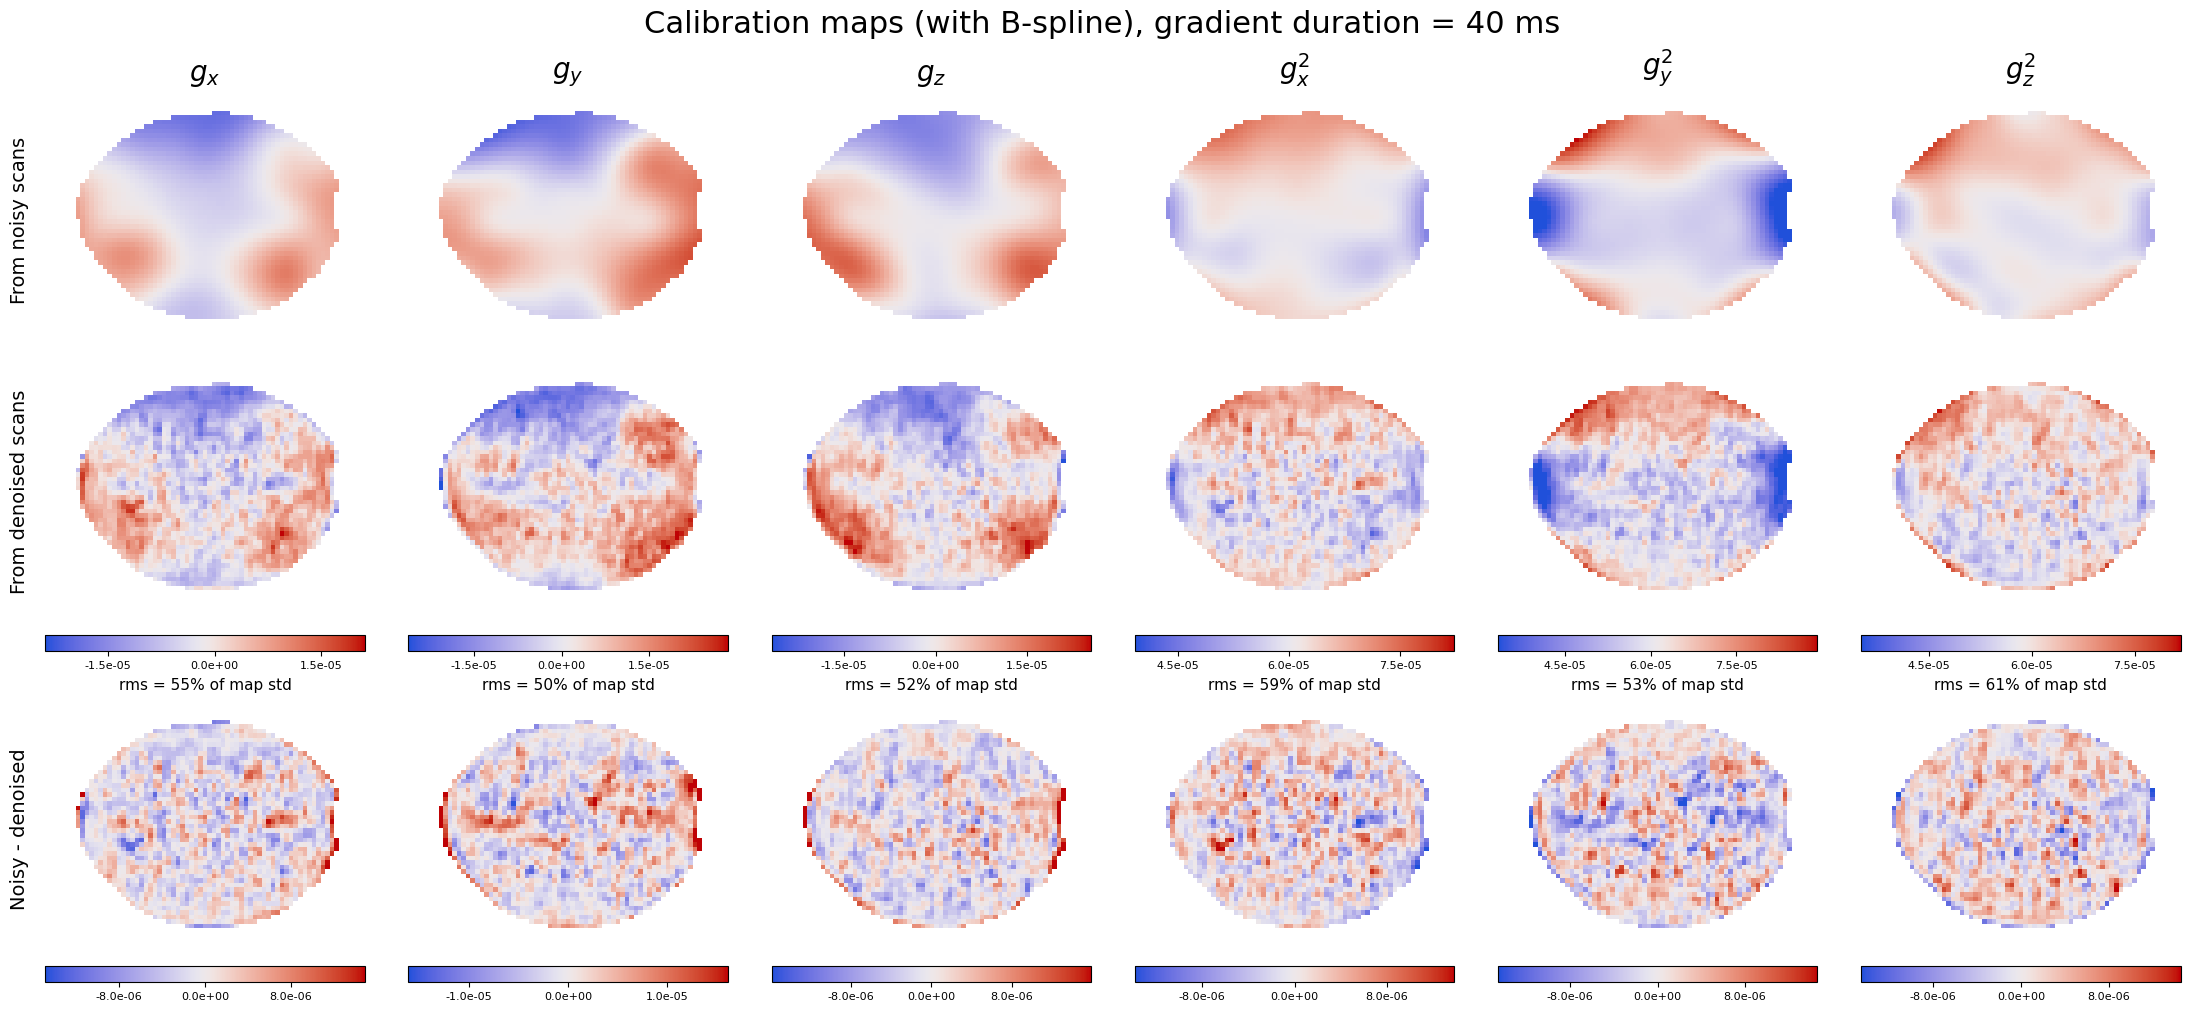

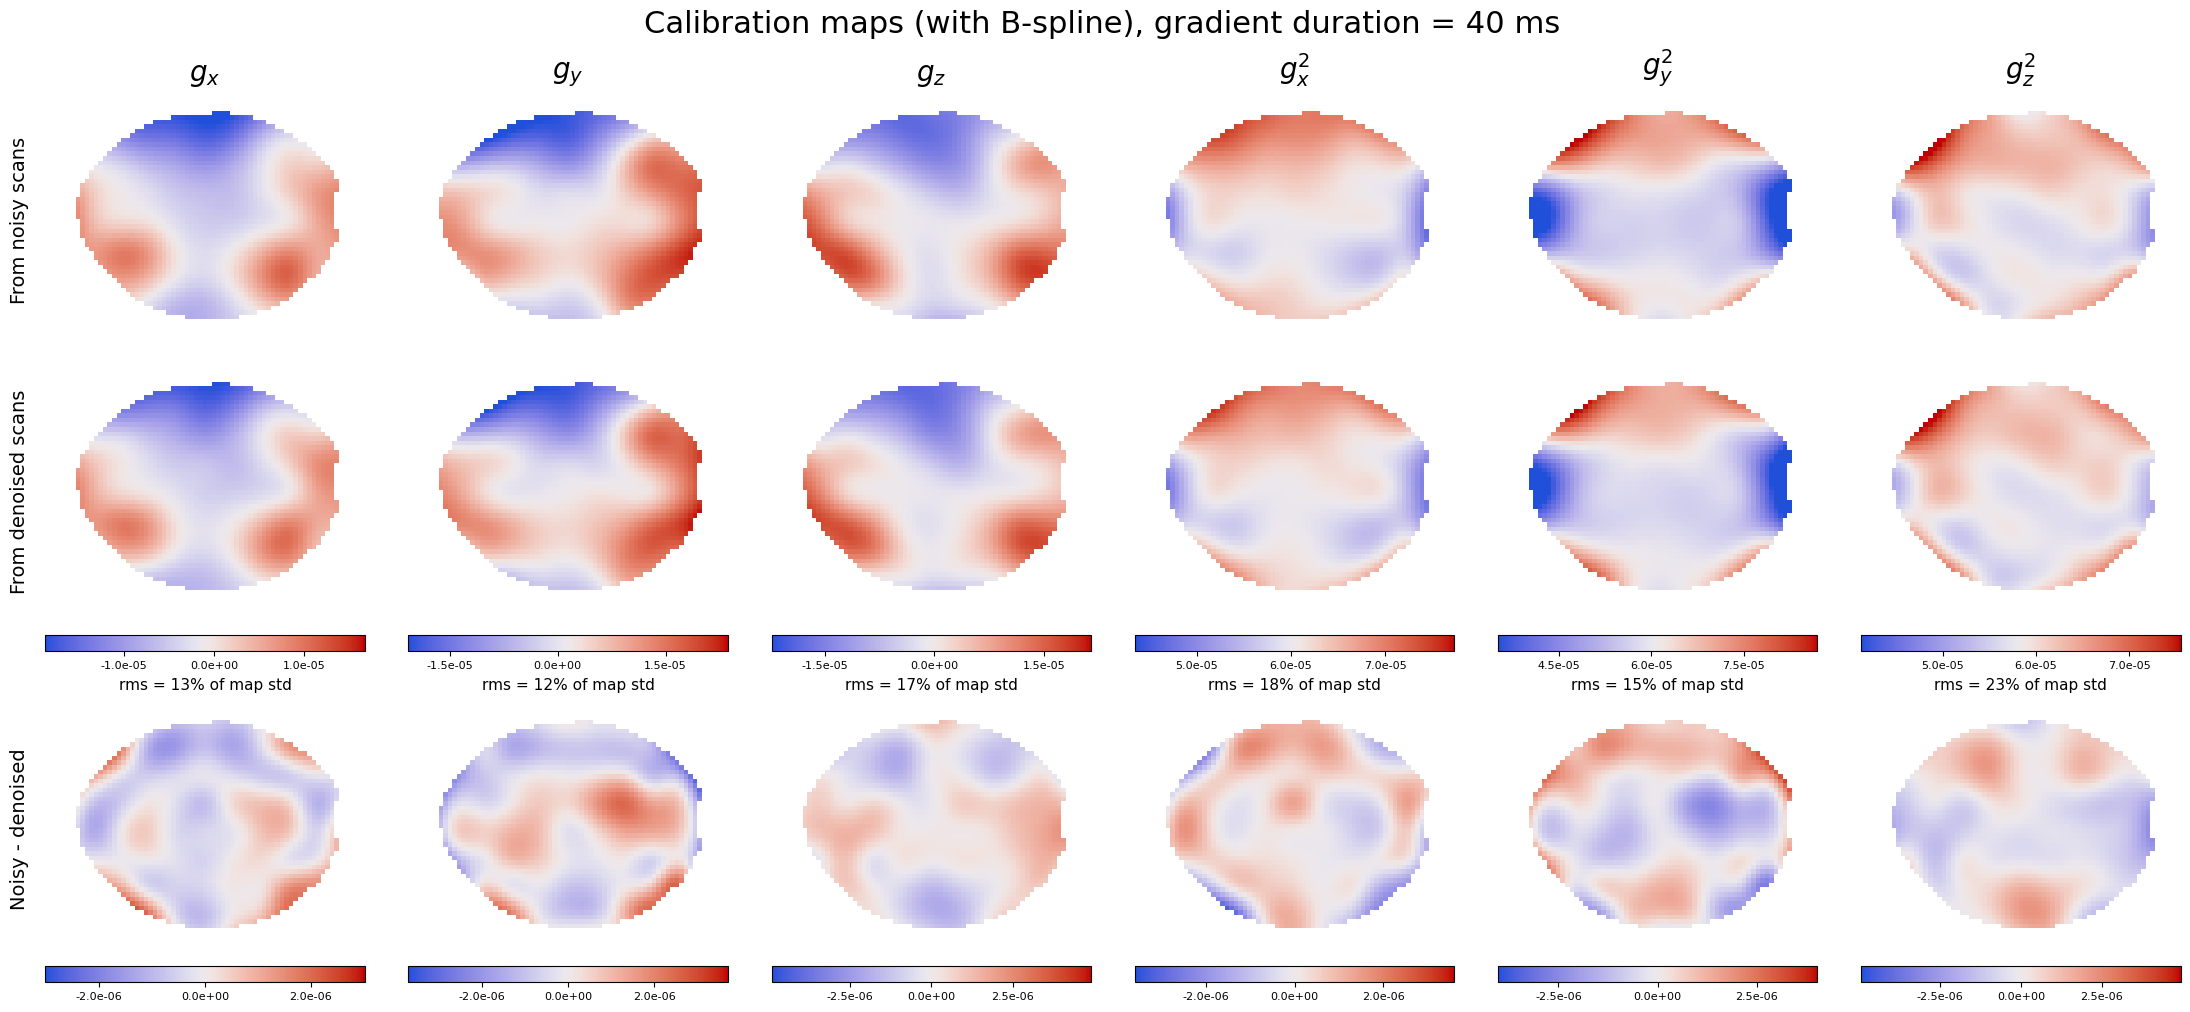

In [ ]:
def plot_noisy_vs_denoised(dur, A_noisy_all, A_denoised_all, label="", fname_suffix="", i_slice=None):

    A_n = A_noisy_all[dur]
    A_d = A_denoised_all[dur]
    if i_slice is None:
        i_slice = A_d.shape[2] // 2

    fig, axes = plt.subplots(3, 6, figsize=(22, 10), constrained_layout=True)
    row_labels = ["From noisy scans", "From denoised scans", "Noisy - denoised"]

    for j, name in enumerate(map_names):

        noisy_map = A_n[..., j]
        denoised_map = A_d[..., j]
        diff_map = noisy_map - denoised_map

        # Noisy and denoised maps share a colour scale, centred on the median of the denoised map
        centre = np.median(denoised_map[core])
        half_range = np.percentile(np.abs(denoised_map[core] - centre), 99)

        # The difference is shown with its own symmetric scale
        diff_lim = np.percentile(np.abs(diff_map[core]), 99)

        for i, (vol, kwargs) in enumerate([(noisy_map, dict(vmin=centre - half_range, vmax=centre + half_range)),
                                           (denoised_map, dict(vmin=centre - half_range, vmax=centre + half_range)),
                                           (diff_map, dict(vmin=-half_range, vmax=half_range))]):

            plot_slice = np.where(core[..., i_slice], vol[..., i_slice], np.nan)
            im = axes[i, j].imshow(plot_slice, cmap=cc.cm.coolwarm, **kwargs)
            axes[i, j].set_axis_off()

            if i == 1:
                maps_im = im

        rel_diff = 100 * np.sqrt(np.mean(diff_map[core]**2)) / denoised_map[core].std()
        axes[0, j].set_title(name, fontsize=20)
        axes[2, j].set_title(f"rms = {rel_diff:.0f}% of map std", fontsize=11)

        cbar_maps = fig.colorbar(maps_im, ax=axes[:2, j], location="bottom", shrink=0.9, pad=0.02, format="%.1e")
        cbar_diff = fig.colorbar(im, ax=axes[2, j], location="bottom", shrink=0.9, pad=0.02, format="%.1e")
        for cbar in (cbar_maps, cbar_diff):
            cbar.ax.tick_params(labelsize=8)
            cbar.locator = MaxNLocator(nbins=4)
            cbar.update_ticks()

    for i, row_label in enumerate(row_labels):
        axes[i, 0].text(-0.08, 0.5, row_label, transform=axes[i, 0].transAxes, rotation=90,
                        ha="right", va="center", fontsize=14)

    fig.suptitle(f"Calibration maps{label}, gradient duration = {int(round(dur * 1e3))} ms", fontsize=22)

    fig.savefig(plot_dir / f"noisy_vs_denoised_A_DUR_{int(round(dur * 1e3))}{fname_suffix}.png", dpi=200, bbox_inches="tight")
    plt.show()


for dur in A_denoised:
    plot_noisy_vs_denoised(dur, A_noisy, A_noisy_nobs, label=" (with B-spline)")
    plot_noisy_vs_denoised(dur, A_noisy, A_denoised, label=" (with B-spline)")

### WITHOUT B-SPLINE SMOOTHING

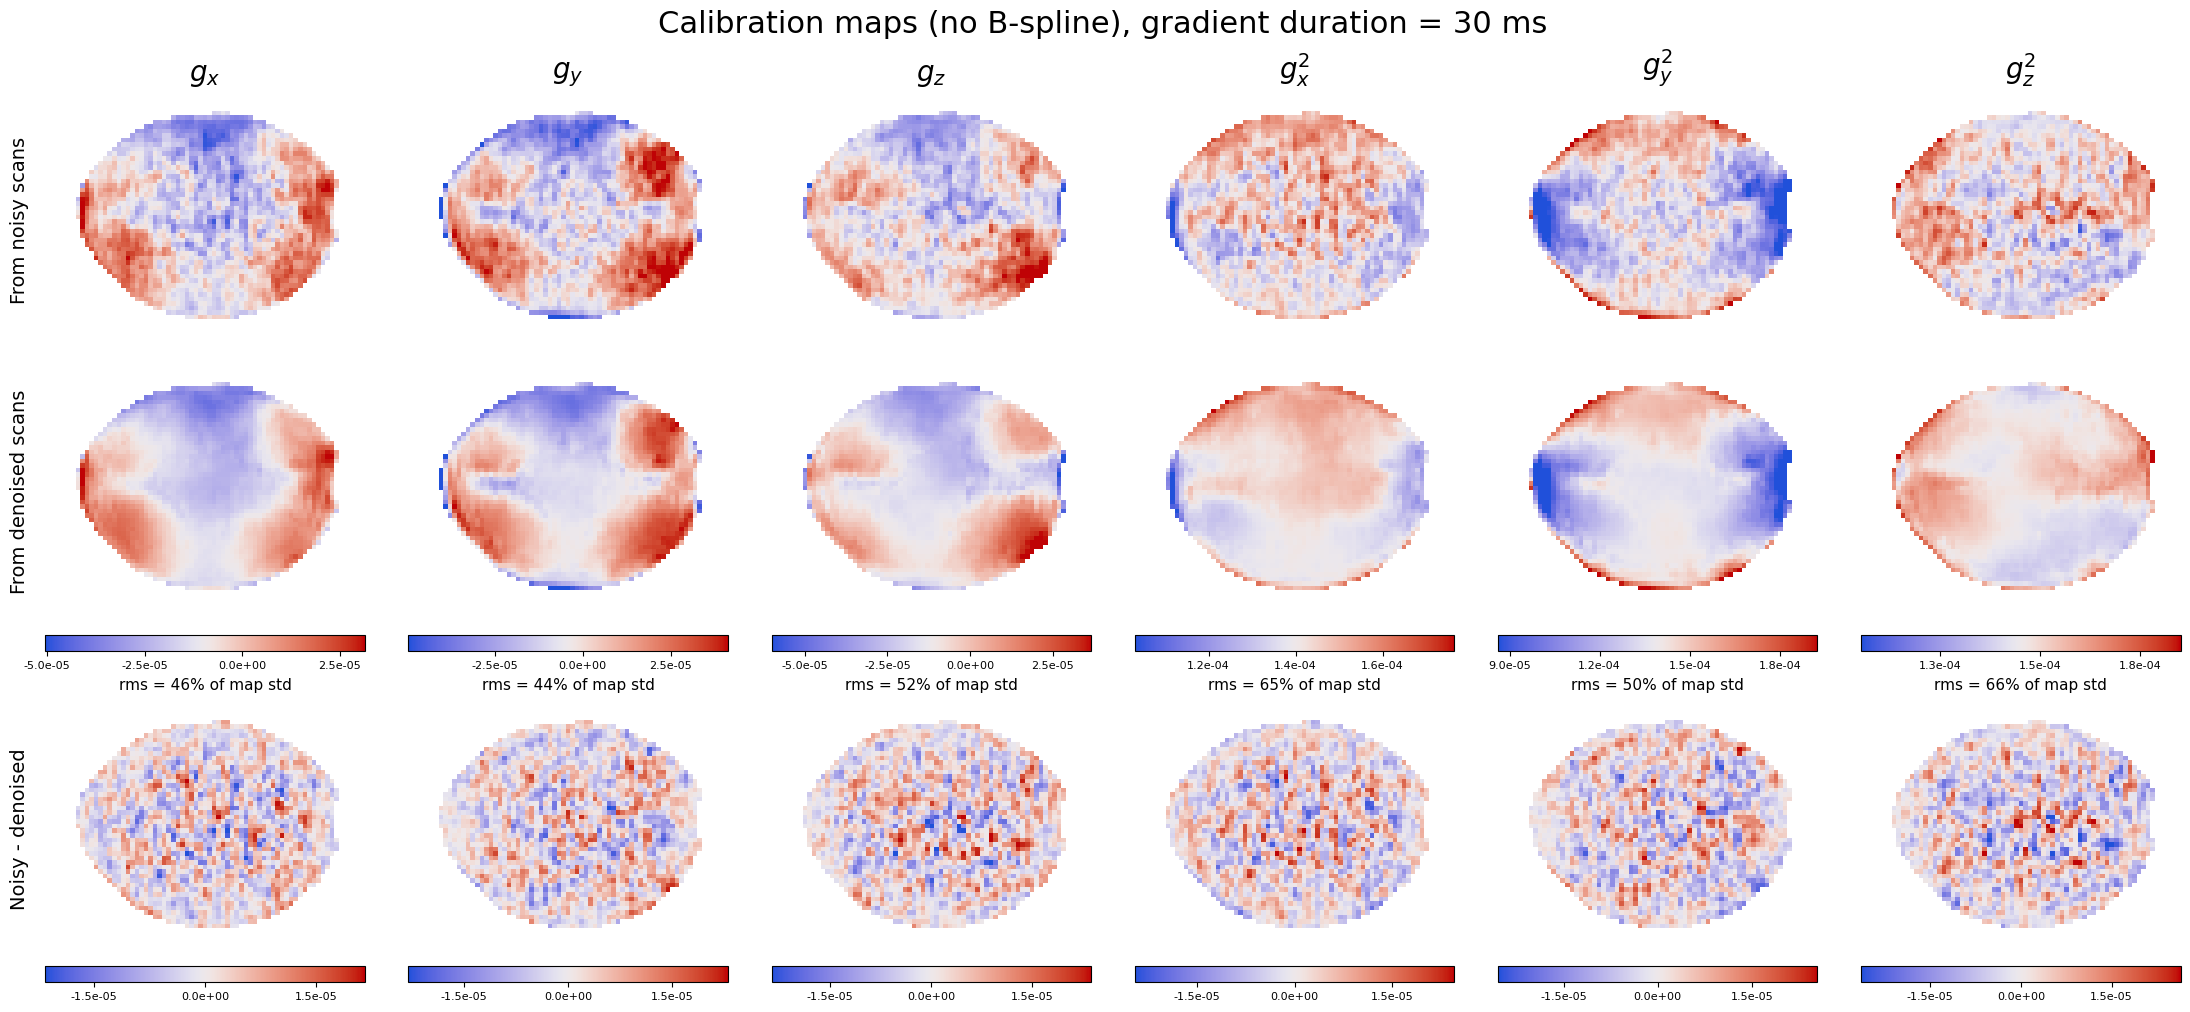

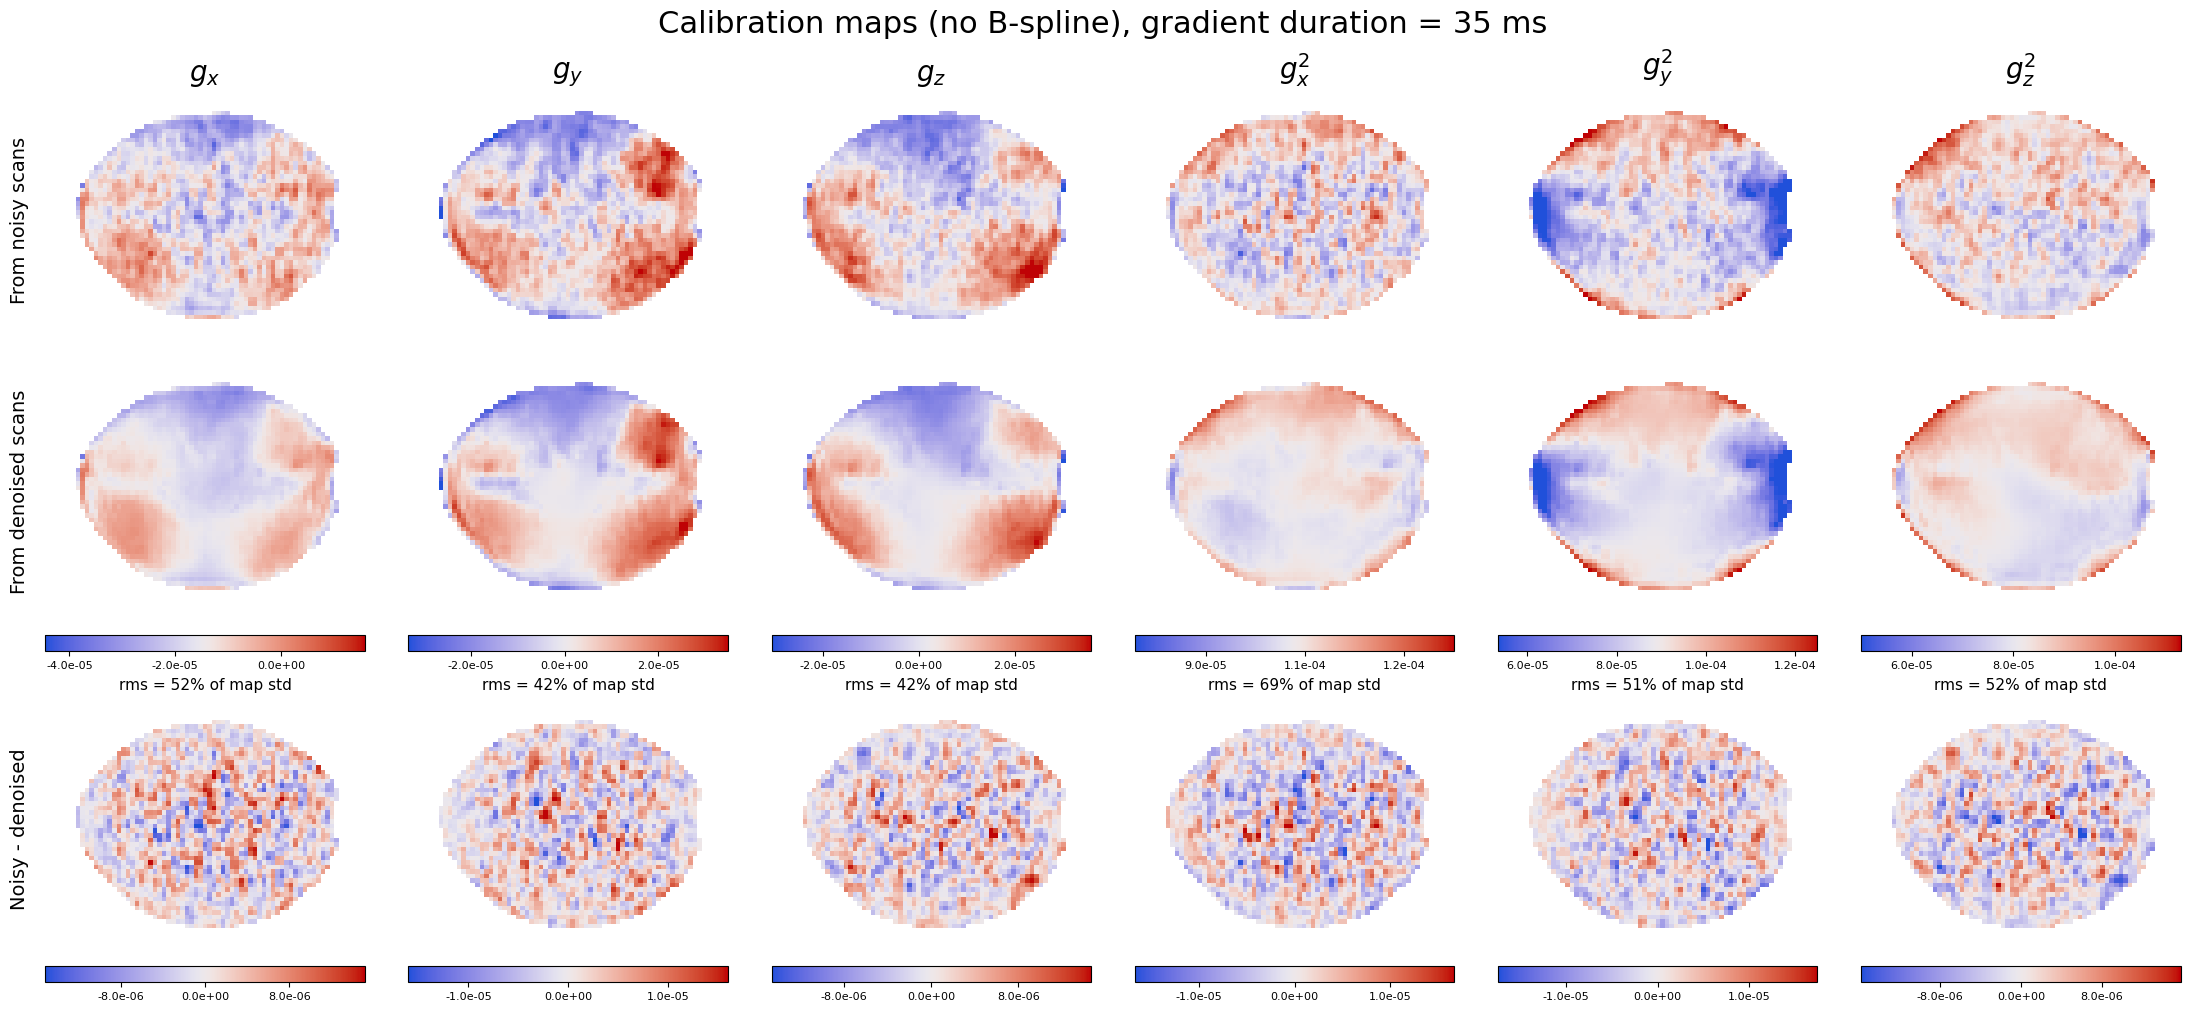

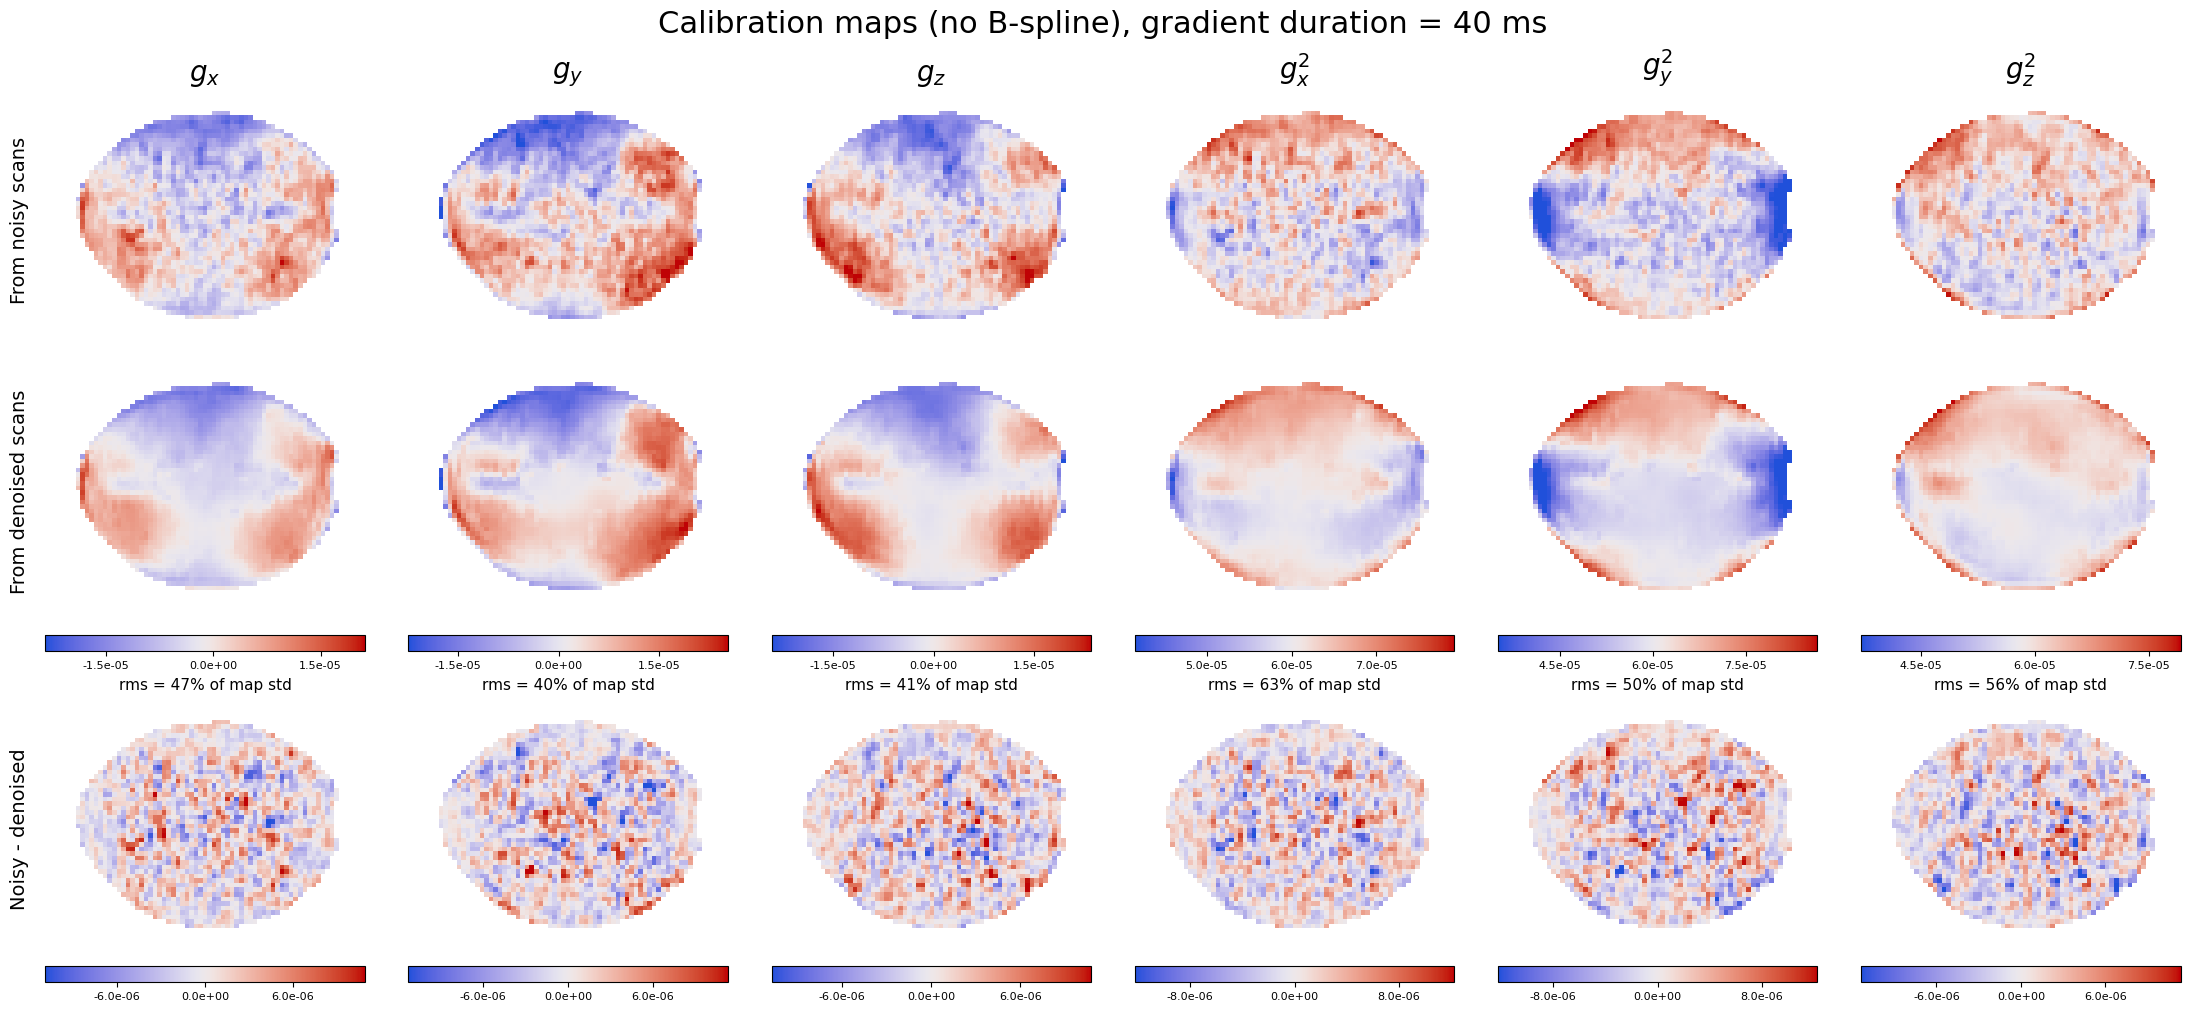

In [7]:
for dur in A_denoised_nobs:
    plot_noisy_vs_denoised(dur, A_noisy_nobs, A_denoised_nobs, label=" (no B-spline)", fname_suffix="_no_bspline")